# Tutorial 4 — Inferring a distribution from a small dataset

Notebook of the programming section of chapter 4 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).

**How to run it.** Run all cells from top to bottom.
* *Locally (Jupyter):* run it from its folder; the data file is read from the folder if present.
* *On Google Colab:* [open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_4/Tutorial_4.ipynb)
  and run all cells; the data file is downloaded automatically.

The random number generator is seeded, so that the notebook reproduces the figures and numbers of the book.

In [2]:
import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import scipy as sp
import scipy.stats
import scipy.optimize
import os, sys, urllib.request
%matplotlib inline

# Book repository, from which missing data files are downloaded
BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'
FOLDER = 'Tutorial_4/'
IN_COLAB = 'google.colab' in sys.modules

def get_data(fname, sources=()):
    """Return fname if it is in the working folder; otherwise try to download it from the
    book repository and from `sources`; on Colab, as a last resort, ask to upload it."""
    if os.path.exists(fname):
        return fname
    for url in [BOOK_REPO + FOLDER + fname] + list(sources):
        try:
            urllib.request.urlretrieve(url, fname)
            print('downloaded', fname, 'from', url)
            return fname
        except Exception:
            pass
    if IN_COLAB:
        from google.colab import files
        print(f'Please upload {fname}')
        files.upload()
        if os.path.exists(fname):
            return fname
    raise FileNotFoundError(f'{fname} not found: download it into the folder of this notebook')

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

np.random.seed(0)   # fixed seed: reproduces the run shown in the book

## Import data

Results of international football matches between men's national teams, by Mart Jürisoo
([Kaggle](https://www.kaggle.com/datasets/martj42/international-football-results-from-1872-to-2017),
[GitHub](https://github.com/martj42/international_results), CC0). The book uses the version of
5 January 2025, with 47,980 matches, provided as `results.csv` in the book repository. The dataset is
updated regularly: if `results.csv` cannot be found, the current version is downloaded from GitHub and
cut at 5 January 2025; since matches are occasionally added retrospectively, the numbers may then
differ slightly from those of the book.

In [4]:
try:
    football_data = pd.read_csv(get_data('results.csv'))
except FileNotFoundError:
    football_data = pd.read_csv('https://raw.githubusercontent.com/martj42/international_results/master/results.csv')
    football_data = football_data[football_data.date <= '2025-01-05'].reset_index(drop=True)
print(len(football_data), 'matches')

47980 matches


In [5]:
football_data

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False
...,...,...,...,...,...,...,...,...,...
47975,2024-12-31,Oman,Saudi Arabia,2,1,Gulf Cup,Sulaibikhat,Kuwait,True
47976,2024-12-31,Kuwait,Bahrain,0,1,Gulf Cup,Kuwait City,Kuwait,False
47977,2025-01-02,Vietnam,Thailand,2,1,ASEAN Championship,Việt Trì,Vietnam,False
47978,2025-01-04,Oman,Bahrain,1,2,Gulf Cup,Kuwait City,Kuwait,True


In [6]:
ngoals = np.concatenate((np.array(football_data.home_score),np.array(football_data.away_score)))
np.random.shuffle(ngoals)
Ndata=len(ngoals)
print('Number of data:',Ndata)
print('Maximum number of goals:',np.max(ngoals))
print('Mean number of goals:',np.mean(ngoals))
print('Standard deviation:',np.std(ngoals))
print('Probability of zero goals:',np.mean(ngoals==0))
print('Average excess of goals above x=10:',np.mean((ngoals-10)*(ngoals>=10)))
print('Average excess of goals conditioned to x>=10:',np.mean((ngoals-10)*(ngoals>=10))/np.mean((ngoals>=10)))

Number of data: 95960
Maximum number of goals: 31
Mean number of goals: 1.4705398082534389
Standard deviation: 1.6233906515577048
Probability of zero goals: 0.30651313047102957
Average excess of goals above x=10: 0.007503126302626094
Average excess of goals conditioned to x>=10: 2.4242424242424243


## Comparison to a Poisson distribution

In [8]:
print('Probability of zero goals:',sp.stats.poisson.pmf(0, np.mean(ngoals)))
print('Average excess of goals above x=10:',np.sum([(x-10)*(x>=10)*sp.stats.poisson.pmf(x, np.mean(ngoals)) for x in range(100)]))

Probability of zero goals: 0.22980140300544993
Average excess of goals above x=10: 5.177754351936389e-07


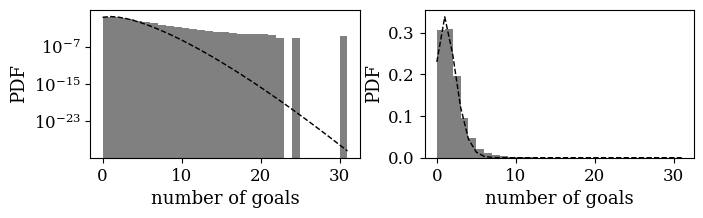

In [9]:
fig, ((ax0, ax2)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax0.hist(ngoals, bins=range(0,32), facecolor='grey',density=True);
ax0.set_yscale('log')
ax0.set_xlabel('number of goals')
ax0.set_ylabel('PDF')
ax0.plot(bins, sp.stats.poisson.pmf(bins, np.mean(ngoals)), '--', color ='black', linewidth=3)

n, bins, patches = ax2.hist(ngoals, bins=range(0,32), facecolor='grey',density=True);
ax2.set_xlabel('number of goals')
ax2.set_ylabel('PDF')
ax2.plot(bins, sp.stats.poisson.pmf(bins, np.mean(ngoals)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("hist_Poisson.pdf", FULL)
plt.show()

## Maximum entropy distribution

In [11]:
def findmaxent(k,indata):

    def maxent(l):
      denom1 = -1 + np.exp(-l[1])
      denom2 = -1 + np.exp(l[1])
      denom3 = 1 - np.exp(l[1] + l[2])

      # Define the shared denominator for all functions
      common_denom = (np.exp(l[0]) + 1 / denom1 + np.exp(k * l[1]) * (1 / denom2 + 1 / denom3))
      f1 = np.exp(l[0]) / common_denom
      f2 = ((np.exp(-l[1]) / denom1**2 +
           np.exp(k * l[1]) * (-np.exp(l[1]) / denom2**2 +
                               np.exp(l[1] + l[2]) / denom3**2) +
           np.exp(k * l[1]) * (1 / denom2 + 1 / denom3) * k) / common_denom)
      f3 = (np.exp(l[1] + k * l[1] + l[2]) / (denom3**2 * common_denom))
      return [f1-np.mean(indata==0), f2-np.mean(indata), f3-np.mean((indata-k)*(indata>=k))]

    root = sp.optimize.fsolve(maxent, [-0.5,-0.5, 0.3])
    return root

def pmaxent(x,k,l):
    denom1 = -1 + np.exp(-l[1])
    denom2 = -1 + np.exp(l[1])
    denom3 = 1 - np.exp(l[1] + l[2])
    Z = np.exp(l[0]) + 1 / denom1 + np.exp(k * l[1]) * (1 / denom2 + 1 / denom3)
    return np.exp(l[0]*(x==0) + l[1]*x + l[2]*(x-k)*(x>=k))/Z

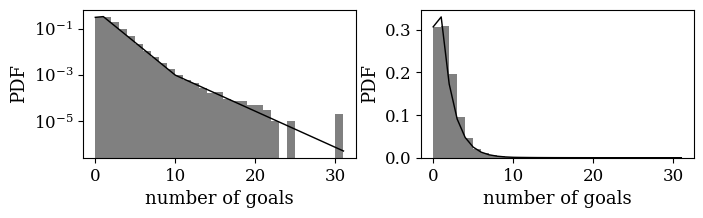

In [12]:
k=10
root = findmaxent(k,ngoals)

fig, ((ax0, ax2)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax0.hist(ngoals, bins=range(0,32), facecolor='grey',density=True);
ax0.set_yscale('log')
ax0.set_xlabel('number of goals')
ax0.set_ylabel('PDF')
ax0.plot(bins, pmaxent(bins,k,root), '-', color ='black', linewidth=3)

n, bins, patches = ax2.hist(ngoals, bins=range(0,32), facecolor='grey',density=True);
ax2.set_xlabel('number of goals')
ax2.set_ylabel('PDF')
ax2.plot(bins, pmaxent(bins,k,root), '-', color ='black', linewidth=3)

plt.tight_layout()
save("hist_alldata.pdf", FULL)
plt.show()

## Maximum entropy distribution with limited data



In [14]:
k=10
nd=1024
ris=[]
for i in range(7):
  ris.append(list(range(nd,nd+1))+list(findmaxent(k,ngoals[:nd]))+list([np.mean(ngoals[:nd]==0),np.mean(ngoals[:nd]),np.mean((ngoals[:nd]-k)*(ngoals[:nd]>=k))]))
  nd=nd*2
ris.append(list(range(Ndata,Ndata+1))+list(findmaxent(k,ngoals))+list([np.mean(ngoals==0),np.mean(ngoals),np.mean((ngoals-k)*(ngoals>=k))]))
for sublist in ris:
    print(sublist)

[1024, -0.7419857869796954, -0.6753228106753494, 0.314598396955945, 0.314453125, 1.408203125, 0.005859375]
[2048, -0.685942693205935, -0.6482668083209522, 0.2766123308531048, 0.314453125, 1.4501953125, 0.0068359375]
[4096, -0.6654021737794684, -0.6282121490071055, 0.20180886934281983, 0.309814453125, 1.489501953125, 0.006103515625]
[8192, -0.7072326485499212, -0.6275572465751298, 0.29664185911168073, 0.3004150390625, 1.5211181640625, 0.0103759765625]
[16384, -0.7329994052572625, -0.6460493652267482, 0.27626563605773374, 0.30340576171875, 1.47747802734375, 0.00714111328125]
[32768, -0.706912020453587, -0.6422706073024305, 0.294899449129051, 0.30718994140625, 1.47821044921875, 0.00830078125]
[65536, -0.711937694041914, -0.6453341979285889, 0.28134132804643025, 0.3075408935546875, 1.4704742431640625, 0.0073699951171875]
[95960, -0.7200004579581736, -0.6468912221225579, 0.2880392611813639, 0.30651313047102957, 1.4705398082534389, 0.007503126302626094]


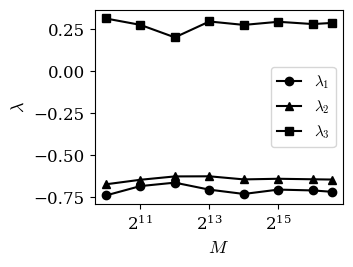

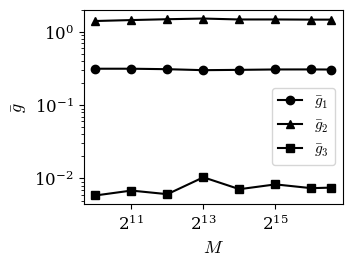

In [15]:
ris2=np.array(ris)
plt.xscale('log', base=2)
plt.plot(ris2[:,0],ris2[:,1],'o-',color='black',label=r'$\lambda_1$')
plt.plot(ris2[:,0],ris2[:,2],'^-',color='black',label=r'$\lambda_2$')
plt.plot(ris2[:,0],ris2[:,3],'s-',color='black',label=r'$\lambda_3$')
plt.xlabel(r'$M$')
plt.ylabel(r'$\lambda$')
plt.legend()
plt.tight_layout()
save("lambda.pdf", HALF)
plt.show()

plt.xscale('log', base=2)
plt.yscale('log')
plt.plot(ris2[:,0],ris2[:,4],'o-',color='black',label=r'$\bar g_1$')
plt.plot(ris2[:,0],ris2[:,5],'^-',color='black',label=r'$\bar g_2$')
plt.plot(ris2[:,0],ris2[:,6],'s-',color='black',label=r'$\bar g_3$')
plt.xlabel(r'$M$')
plt.ylabel(r'$\bar g$')
plt.legend(loc="center right", bbox_to_anchor=(1, 0.4))
plt.tight_layout()
save("g.pdf", HALF)
plt.show()


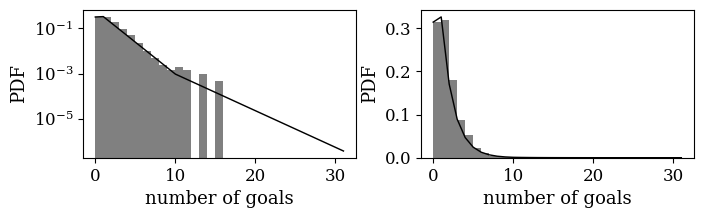

In [16]:
nd=2048
root = findmaxent(k,ngoals[:nd])

fig, ((ax0, ax2)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax0.hist(ngoals[:nd], bins=range(0,32), facecolor='grey',density=True);
ax0.set_yscale('log')
ax0.set_xlabel('number of goals')
ax0.set_ylabel('PDF')
#ax0.plot(bins, sp.stats.poisson.pmf(bins, np.mean(np.mean(ngoals))), '--', color ='black', linewidth=3)
ax0.plot(bins, pmaxent(bins,k,root), '-', color ='black', linewidth=3)

n, bins, patches = ax2.hist(ngoals[:nd], bins=range(0,32), facecolor='grey',density=True);
#ax2.set_yscale('log')
ax2.set_xlabel('number of goals')
ax2.set_ylabel('PDF')
#ax2.plot(bins, sp.stats.poisson.pmf(bins, np.mean(np.mean(ngoals))), '--', color ='black', linewidth=3)
ax2.plot(bins, pmaxent(bins,k,root), '-', color ='black', linewidth=3)

plt.tight_layout()
save("hist_2048.pdf", FULL)
plt.show()